# Lab 2 · What an average hides
## Data Science Fundamentals — Week 2: Describing Data
**Mohammad Sabokrou · New Uzbekistan University**

**Your job:** use evidence to explain data and make a defensible decision. The Python is provided; programming complexity earns no extra credit.

**Name:** …   **Student ID:** enter in the setup cell below.

### How to work
1. Open this notebook in Google Colab or Jupyter. Run the setup with your own ID.
2. Work from top to bottom. Where asked, write a prediction **before** running the next cell. Keep the prediction even if it is wrong; explain what you learned.
3. Double-click an **Answer** cell to write. Use your own generated numbers and refer to specific plots. A number without an interpretation is incomplete.
4. Run the supplied code; change only the explicitly labelled settings. You are responsible for understanding and explaining the results you submit.
5. Keep the same ID throughout. Restart and run all cells after finishing; save the notebook with outputs.

**Suggested pace:** setup 5 min; sections 1–8: 10, 15, 15, 15, 15, 10, 15, 15 min; final check 5 min (120 min total). Finish the written reflection after class if needed.

### What varies between students?
Your ID determines the data, eight-number exercise, selected record, histogram settings, and decision scenario. The concepts and workload stay comparable. Reusing an ID gives the same case. Different IDs are not a guarantee that every individual number differs.

All records are **synthetic teaching data**, not real university records. There are no downloads, joins, or missing code blocks to debug.

**Evidence standard:** answers should contain a claim, a number or plot observation from your case, and a reason or limitation. We assess statistical reasoning, appropriate methods, and reproducible evidence—not Python fluency.

In [1]:
# SETUP — edit only STUDENT_ID. Integers and quoted IDs both work.
STUDENT_ID = "250104"
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

STUDENT_ID = str(STUDENT_ID).strip()
if not (STUDENT_ID.isascii() and STUDENT_ID.isdigit() and 6 <= len(STUDENT_ID) <= 12):
    raise ValueError("Replace YOUR_ID with your own 6–12 digit student ID, then run again.")
seed = int.from_bytes(hashlib.sha256(('FDS-Lab2-v1:' + STUDENT_ID).encode()).digest()[:8], 'big')
rng = np.random.default_rng(seed)
case_code = hashlib.sha256(('FDS-Lab2-v1:' + STUDENT_ID).encode()).hexdigest()[:10]
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.options.display.float_format = '{:.3f}'.format
N = 240
programme = rng.choice(['A', 'B'], N, p=[.55, .45])
entry = np.clip(rng.normal(rng.uniform(62,68), rng.uniform(8,11), N), 0, 100)
minutes = rng.lognormal(rng.uniform(4.1,4.4), .85, N)
# Two different teaching groups: their score patterns intentionally differ.
assessment = np.clip(rng.normal(np.where(programme == 'A', 43, 78), 4.5), 0, 100)
satisfaction = rng.choice([1.,2.,3.,4.,5.], N, p=[.08,.12,.2,.35,.25])
satisfaction[rng.choice(N, size=int(rng.integers(35,61)), replace=False)] = np.nan
students = pd.DataFrame({'record_id':np.arange(1,N+1), 'programme':programme,
    'entry_score':entry, 'weekly_minutes':minutes,
    'assessment_score':assessment, 'satisfaction':satisfaction})
small = np.sort(rng.choice(np.arange(35,86), 8, replace=False)).astype(float)
focus_index = int(np.argmax(entry))
coarse_bins = int(rng.choice([2,3,4]))
fine_bins = int(rng.choice([35,40,45]))
scenario = str(rng.choice(['typical use', 'total workload']))
print('Case:',case_code, '| ID:',STUDENT_ID, '| Final decision:',scenario)
print('Keep this case code in your submission. Setup complete.')

Case: c4a083519c | ID: 250104 | Final decision: total workload
Keep this case code in your submission. Setup complete.


## 1 · Who and what are we describing? (10 min)
One row is one synthetic student observed in the same week. Scores are points out of 100; minutes are minutes per student in that week. Satisfaction is an **ordered category** from 1 (lowest) to 5 (highest); equal numerical steps need not represent equal changes in feeling. Programme A/B are category labels; record IDs are identifiers.

The next cell displays the data and counts. `count()` excludes missing values; `len()` counts rows. No missing value is replaced by zero.

In [2]:
display(students.head())
valid = students['satisfaction'].count()
print(f'Total rows: {len(students)}; valid satisfaction: {valid}; missing: {len(students)-valid}')
print(f'Response rate: {100*valid/len(students):.1f}%')
display(students['satisfaction'].value_counts().sort_index().rename('responses'))
print('Most common programme(s):', students['programme'].mode().tolist())

,record_id,programme,entry_score,weekly_minutes,assessment_score,satisfaction
0,1,A,55.480,25.073,48.414,4.000
1,2,A,58.896,32.888,37.212,4.000
2,3,B,46.829,23.502,83.275,3.000
3,4,A,67.384,138.742,38.133,NaN
4,5,A,77.102,20.219,40.752,5.000


Total rows: 240; valid satisfaction: 200; missing: 40
Response rate: 83.3%


,responses
satisfaction,
1.000,20
2.000,21
3.000,36
4.000,64
5.000,59


Most common programme(s): ['A']


### Your reasoning
**1A.** State the observational unit and the denominator for the satisfaction response rate. Why is the denominator for a mean of recorded satisfaction responses different? One row represents one student. For the satisfaction response rate, I use all 240 students as the denominator because I want to know how many students actually gave a response. There are 200 valid responses, so the response rate is 83.3%. For the mean satisfaction, I only use the 200 students who actually answered because the 40 missing values are not satisfaction scores.

**1B.** A colleague replaces missing satisfaction with zero. Explain why this changes the meaning. Can the responses establish what *all* students feel? Replacing the missing answers with 0 is not correct because a missing answer does not mean the student chose the lowest satisfaction. It changes the meaning of the data. Also, we cannot say exactly what all 240 students feel because 40 students did not give a satisfaction response.

**1C.** Which is meaningful: the mode of programme, the mean of record ID, or the mean of programme coded A=1/B=2? Explain. For satisfaction, explain why the category frequency table adds information that a mean alone hides.

**Answer:** The mode of programme is meaningful because programme A/B are categories. The mean of record ID is not meaningful because the ID is just an identifier. The mean of A=1 and B=2 is also not really meaningful because those numbers are just codes. For satisfaction, the frequency table is useful because it shows how many students chose each category. For example, 64 chose 4 and 59 chose 5, which a single mean would not show.

## 2 · Eight numbers, by hand first (15 min)
Run the next cell to obtain your eight numbers. Before running the checking cell, calculate their mean, median, **sample variance and sample SD** using a calculator if useful. Show intermediate steps; no Python writing is required.

Mean = sum / n. Deviations = value − mean. Sample variance = sum of squared deviations / (n−1). Sample SD = square root of sample variance.

In [3]:
print('Your eight scores:',small.tolist())

Your eight scores: [37.0, 52.0, 53.0, 57.0, 58.0, 65.0, 66.0, 84.0]


### Your reasoning
**2A.** Record: sum, n, mean, middle two scores, median, eight deviations, sum of squared deviations, sample variance, and sample SD. Include units. Sum = 472
n = 8
Mean = 472 / 8 = 59

The middle two values are 57 and 58.

Median = (57 + 58) / 2 = 57.5

Deviations from the mean:

-22, -7, -6, -2, -1, 6, 7, 25

Squared deviations:

484, 49, 36, 4, 1, 36, 49, 625

Sum of squared deviations = 1284

Sample variance = 1284 / 7 = 183.429 points²

Sample SD = √183.429 = 13.544 points

**2B. Prediction:** if these eight scores were the entire population of interest, would the population SD be larger or smaller? Why?

**Answer:** If these were the whole population, the population SD would be smaller. This is because population variance divides by 8, while sample variance divides by 7. Dividing by the bigger number gives a smaller result.

In [4]:
# CHECK ONLY AFTER YOUR HAND CALCULATIONS
s = pd.Series(small)
display(pd.DataFrame({'score':small,'deviation':small-small.mean(),
                     'squared deviation':(small-small.mean())**2}))
display(pd.Series({'mean':s.mean(),'median':s.median(),
    'sample variance':s.var(ddof=1),'pandas sample SD':s.std(),
    'NumPy population SD':np.std(small), 'NumPy sample SD':np.std(small,ddof=1)}))

,score,deviation,squared deviation
0,37.000,-22.000,484.000
1,52.000,-7.000,49.000
2,53.000,-6.000,36.000
3,57.000,-2.000,4.000
4,58.000,-1.000,1.000
5,65.000,6.000,36.000
6,66.000,7.000,49.000
7,84.000,25.000,625.000


,0
mean,59.000
median,57.500
sample variance,183.429
pandas sample SD,13.544
NumPy population SD,12.669
NumPy sample SD,13.544


### Your reasoning
**2C.** Compare your work with the output. Correct any error and explain its source. Why do the two default SD results differ? State which divisor answers each question; explain why variance has points² but SD has points.

**Answer:** My calculations match the checking cell. The mean is 59, the median is 57.5, the sample variance is 183.429 and the sample SD is 13.544.

## 3 · Middle half, extremes, and sensitivity (15 min)
For the eight scores, use **median of halves**: Q1 is the median of the lower four; Q3 the median of the upper four. For the larger dataset later, use pandas **linear interpolation**. Different stated conventions can legitimately give different quartiles.

Before running, compute the five-number summary and IQR of your eight scores. Then predict what happens if the largest score is accidentally multiplied by 10.

### Your reasoning
**3A.** Give min, Q1, median, Q3, max, and IQR by hand. Interpret the middle-half interval in a sentence. Minimum = 37
Q1 = 52.5
Median = 57.5
Q3 = 65.5
Maximum = 84

IQR = 65.5 - 52.5 = 13

So the middle 50% of the scores are between 52.5 and 65.5 points.

**3B. Prediction:** which will change most after the error: mean or median? Will range, SD, and IQR change? Explain using which observations each measure depends on.

**Answer:** I think the mean will change more than the median because the largest value has a big effect on the mean. The range and SD will also change a lot. The median and IQR should stay the same here because the changed value is at the end and does not affect the middle values.

In [5]:
def half_summary(a):
    a = np.sort(a)
    q1, q3 = np.median(a[:4]), np.median(a[4:])
    return pd.Series({'min':a.min(),'Q1':q1,'median':np.median(a),'Q3':q3,
        'max':a.max(),'mean':a.mean(),'range':np.ptp(a),'IQR':q3-q1,
        'sample variance':np.var(a,ddof=1),'sample SD':np.std(a,ddof=1)})
changed = small.copy(); changed[-1] *= 10
print('Changed scores:',changed.tolist())
display(pd.DataFrame({'original':half_summary(small),'with error':half_summary(changed)}))
print('Original pandas linear quartiles:',pd.Series(small).quantile([.25,.75]).to_dict())

Changed scores: [37.0, 52.0, 53.0, 57.0, 58.0, 65.0, 66.0, 840.0]


,original,with error
min,37.000,37.000
Q1,52.500,52.500
median,57.500,57.500
Q3,65.500,65.500
max,84.000,840.000
mean,59.000,153.500
range,47.000,803.000
IQR,13.000,13.000
sample variance,183.429,77025.429
sample SD,13.544,277.535


Original pandas linear quartiles: {0.25: 52.75, 0.75: 65.25}


### Your reasoning
**3C.** Compare predictions with results, citing at least two numerical changes. Why can the median and IQR stay stable here? Does that make them universally best? The prediction was correct. When 84 changes to 840, the mean goes from 59 to 153.5 and the range goes from 47 to 803. The SD also goes from 13.544 to 277.535. But the median stays at 57.5 and the IQR stays at 13. The median and IQR stay stable because the changed value is the biggest value, so it does not change the middle half. That does not mean they are always the best measures. It depends on what we are trying to describe.

**3D.** Explain any difference between hand and software quartiles. Why is the altered score impossible in this context, whereas a very large number of platform minutes may be valid?

**Answer:**.My hand quartiles are Q1 = 52.5 and Q3 = 65.5. Pandas gives 52.75 and 65.25 because it uses linear interpolation. Both results come from different quartile methods.The value 840 is impossible for a score because the scores are out of 100. However, a very large platform-use number can be possible because minutes do not have a maximum of 100.

## 4 · Look before summarising (15 min)
The next cell plots four numeric columns: entry score, weekly minutes, assessment score, and satisfaction. For the discrete ordinal satisfaction scale, each histogram bin represents one response category. Missing responses are excluded and the valid n is shown.

Read **centre, spread, tail direction, peaks/gaps, and unusual values**. `skew()` gives a sample skewness statistic; its sign is useful evidence, not a complete description of shape.

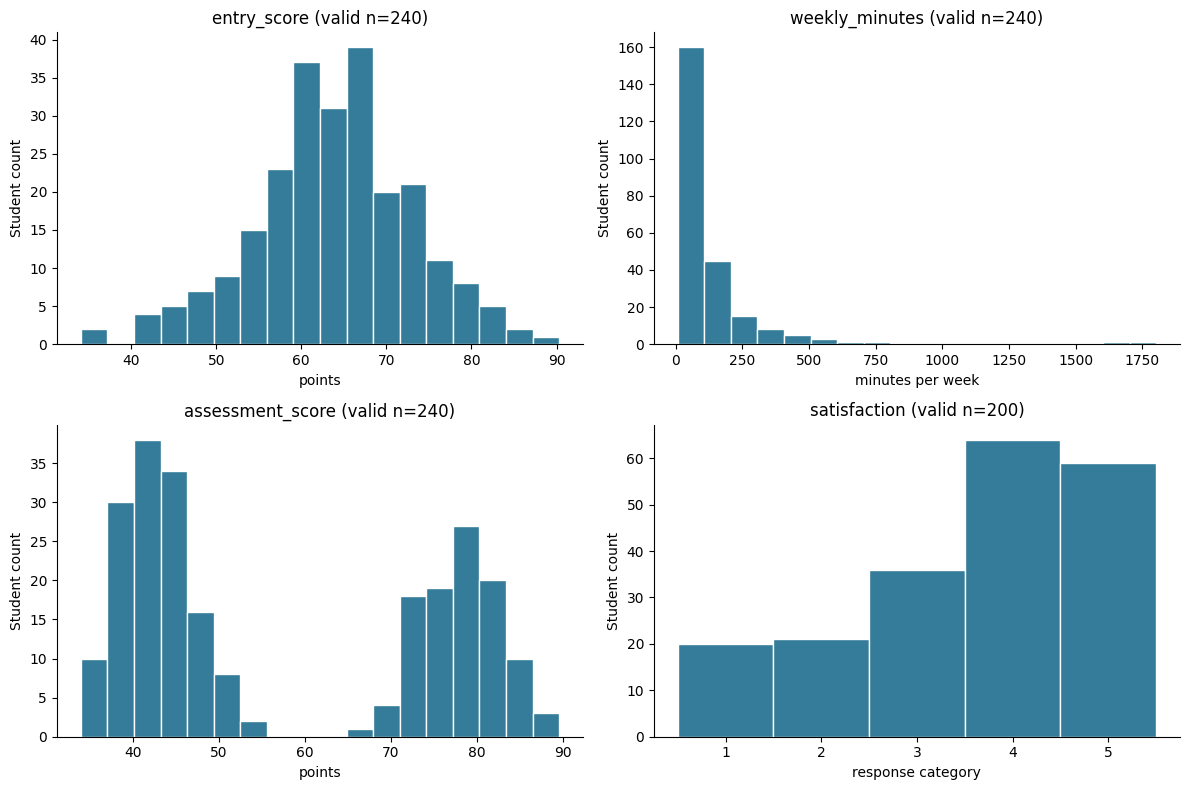

,count,mean,median,std,skew
entry_score,240.000,63.665,64.312,9.358,-0.200
weekly_minutes,240.000,127.706,76.730,186.054,5.936
assessment_score,240.000,57.731,47.771,17.926,0.291


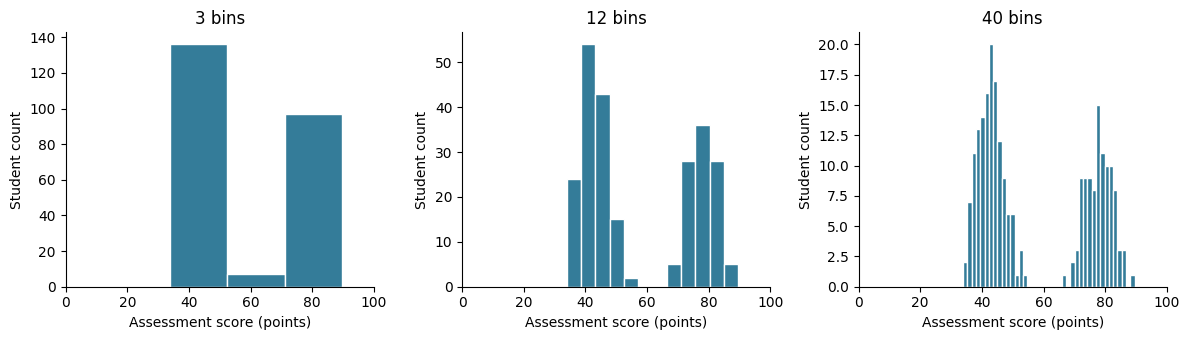

In [6]:
columns = ['entry_score','weekly_minutes','assessment_score','satisfaction']
units = ['points','minutes per week','points','response category']
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax,col,unit in zip(axes.flat,columns,units):
    x=students[col].dropna()
    ax.hist(x,bins=np.arange(.5,6,1) if col=='satisfaction' else 18,
            color='#347c99',edgecolor='white')
    ax.set(title=f'{col} (valid n={len(x)})',xlabel=unit,ylabel='Student count')
plt.tight_layout(); plt.show()
display(students[columns[:3]].agg(['count','mean','median','std','skew']).T)
fig, axes = plt.subplots(1,3,figsize=(12,3.5))
for ax,b in zip(axes,[coarse_bins,12,fine_bins]):
    ax.hist(students.assessment_score,bins=b,color='#347c99',edgecolor='white')
    ax.set(title=f'{b} bins',xlabel='Assessment score (points)',ylabel='Student count',xlim=(0,100))
plt.tight_layout(); plt.show()

### Your reasoning
**4A.** Write one shape sentence for **each of the four columns**. Include plot evidence; do not merely list a skewness number. The entry scores look fairly balanced around the middle, with only a small left skew. The mean is 63.665 and the median is 64.312.

Weekly minutes are very different. They have a strong right tail because some students have much higher usage than most students. The skewness is 5.936.

Assessment scores look like there are two groups because Programme A and B have very different scores. The mean is 57.731 but the median is 47.771.

Satisfaction is mostly toward the higher answers. There are 64 responses of 4 and 59 responses of 5. The mean is 3.605 and the median is 4.

**4B.** Find a column where mean and median disagree. Give both values and explain the mechanism. Which centre and spread would you report for a typical observation? Weekly minutes has a big difference between the mean and median. The mean is 127.706 minutes, but the median is only 76.730 minutes. This happens because a few students have very high usage. For a typical student, I would use the median and IQR because they are less affected by extreme values.

**4C.** Compare the three histogram bin settings. What is concealed or exaggerated? Choose one and justify it. Does changing bins change the underlying mean? . With only 2 histogram bins, a lot of the detail is hidden. Using more bins shows more of the actual shape, although too many bins can also make the graph look noisy. I think a middle number of bins is easier to understand. Changing the bins does not change the actual mean because the mean is calculated from the original values.

**4D.** Does a nearly zero skewness or similar mean/median establish a normal distribution? Use the assessment-score plot to explain.

**Answer:** No. A skewness close to zero does not prove that the data are normally distributed. For example, the assessment scores have different programme groups even though their overall skewness is only 0.291. We need to look at the actual shape as well, not just one number.

## 5 · Boxplots, flags, and hidden groups (15 min)
Box = Q1 to Q3; line = median. Fences = Q1 − 1.5×IQR and Q3 + 1.5×IQR. Whiskers end at the most extreme **observed** values inside the fences; they are not the fences themselves. Dots are candidates for investigation, not automatic deletion.

Here pandas and the plotting convention use linearly interpolated quartiles. Group summaries use sample SD (`ddof=1`).

,0
Q1,44.866
median,76.730
Q3,136.929
IQR,92.063
lower fence,-93.228
upper fence,275.023
lower whisker,7.470
upper whisker,254.016
flagged count,21.000


,record_id,weekly_minutes
5,6,358.660
11,12,565.821
20,21,316.820
21,22,315.775
24,25,1666.230
40,41,346.333


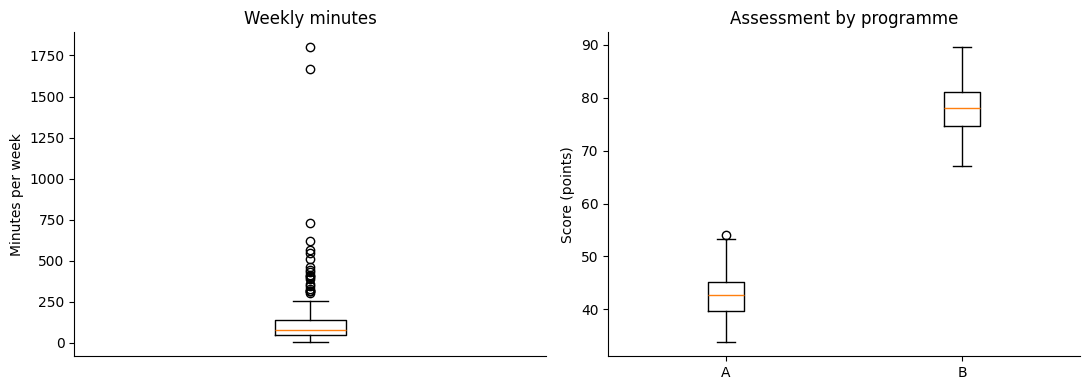

Overall assessment summary:


,assessment_score
count,240.000
mean,57.731
median,47.771
std,17.926


Programme summaries:


,count,mean,median,std
programme,,,,
A,138,42.795,42.705,4.187
B,102,77.938,78.033,4.411


In [7]:
x = students.weekly_minutes
q1,q3=x.quantile([.25,.75]); iqr=q3-q1
lower,upper=q1-1.5*iqr,q3+1.5*iqr
inside=x[(x>=lower)&(x<=upper)]
flagged=students[(x<lower)|(x>upper)]
display(pd.Series({'Q1':q1,'median':x.median(),'Q3':q3,'IQR':iqr,
    'lower fence':lower,'upper fence':upper,'lower whisker':inside.min(),
    'upper whisker':inside.max(),'flagged count':len(flagged)}))
display(flagged[['record_id','weekly_minutes']].head(6))
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].boxplot(x); axes[0].set(ylabel='Minutes per week',title='Weekly minutes',xticks=[])
axes[1].boxplot([students.loc[students.programme==g,'assessment_score'] for g in ['A','B']])
axes[1].set(xticks=[1,2],xticklabels=['A','B'],ylabel='Score (points)',title='Assessment by programme')
plt.tight_layout(); plt.show()
print('Overall assessment summary:')
display(students.assessment_score.agg(['count','mean','median','std']))
print('Programme summaries:')
display(students.groupby('programme').assessment_score.agg(['count','mean','median','std']))

### Your reasoning
**5A.** Using your Q1/Q3, show one fence calculation. State a whisker endpoint and explain why it differs from the corresponding fence. Describe a flagged record using its ID and minutes. Q1 is 44.866 and Q3 is 136.929, so the IQR is 92.063.

Upper fence = 136.929 + 1.5(92.063) = 275.023 minutes.

The upper whisker is 254.016 minutes because the whisker stops at the largest actual observation that is still inside the fence. It does not have to equal the fence itself.

For example, record 6 has 358.660 minutes, so it is flagged as an outlier candidate.

**5B.** Propose two checks before changing that record and one reason to retain it. What would you document if it were corrected? Do not delete it simply because it crosses a fence. Before changing the value, I would check the original platform record and also check if there was a data-entry or unit error. One reason to keep the value is that the student may actually have used the platform for that long. If I corrected it, I would record the old value, the new value, and why I changed it.

**5C.** Compare the overall assessment mean with both programme means and SDs. Would a single support session at the overall average meet both groups' needs? Give evidence and a better plan. Can these data prove that programme membership caused the difference?

**Answer:** The overall assessment mean is 57.731, but Programme A has a mean of 42.795 and Programme B has a mean of 77.938. Their SDs are 4.187 and 4.411. Because the two groups are so different, one support session based only on the overall average would probably not address both groups in the same way. I would use separate support based on the programme results. However, these results do not prove that the programme caused the difference.

### Same mean and SD, different students
The next two small classes have the same mean and sample SD but different shapes. Values are shifted for your case. Inspect them before answering.

In [8]:
centre = int(round(small.mean()))
class_a = centre + np.array([-20,0,0,0,0,0,0,20])
class_b = centre + np.array([-10,-10,-10,-10,10,10,10,10])
for name,a in [('Class A',class_a),('Class B',class_b)]:
    print(name, a.tolist(), '| mean:',a.mean(),'| sample SD:',round(a.std(ddof=1),3))

Class A [39, 59, 59, 59, 59, 59, 59, 79] | mean: 59.0 | sample SD: 10.69
Class B [49, 49, 49, 49, 69, 69, 69, 69] | mean: 59.0 | sample SD: 10.69


### Your reasoning
**5D.** Sketch or describe each shape. Explain why the same mean and SD can lead to different tutoring plans. What information did the two statistics discard?

**Answer:** Class A has most of its students at 59, with one student at 39 and one at 79. Class B has two groups: four students at 49 and four students at 69.
Both classes have the same mean of 59 and the same sample SD of 10.69, but the shapes are clearly different. This could lead to different tutoring plans because Class B looks like it has two groups of students, while Class A mostly has students around the centre. The mean and SD do not show the full shape of the data. They hide things like groups, gaps and where most of the students are.

## 6 · When does 68–95–99.7 help? (10 min)
A normal model predicts approximately 68%, 95%, and 99.7% within 1, 2, and 3 SD of its mean. This is **not a guarantee for a finite dataset**, and symmetry alone is insufficient. We use sample mean/SD here to compare observed proportions with the model.

In [9]:
rows=[]
for col in ['entry_score','weekly_minutes','assessment_score']:
    x=students[col]; m=x.mean(); sd=x.std(ddof=1)
    for k in [1,2,3]:
        rows.append({'column':col,'SD distance':k,'lower':m-k*sd,'upper':m+k*sd,
                     'observed %':100*x.between(m-k*sd,m+k*sd).mean(),
                     'normal model %':{1:68,2:95,3:99.7}[k]})
display(pd.DataFrame(rows))

,column,SD distance,lower,upper,observed %,normal model %
0,entry_score,1,54.307,73.023,69.167,68.000
1,entry_score,2,44.950,82.380,94.583,95.000
2,entry_score,3,35.592,91.738,99.583,99.700
3,weekly_minutes,1,-58.348,313.761,91.667,68.000
4,weekly_minutes,2,-244.403,499.815,97.083,95.000
5,weekly_minutes,3,-430.457,685.870,98.750,99.700
6,assessment_score,1,39.804,75.657,56.250,68.000
7,assessment_score,2,21.878,93.583,100.000,95.000
8,assessment_score,3,3.951,111.510,100.000,99.700


### Your reasoning
**6A.** Give your entry-score interval within 1 SD and observed percentage. Explain why it need not be exactly 68%. The entry-score mean is 63.665 and the SD is 9.358. So the 1-SD interval is:

63.665 − 9.358 = 54.307

63.665 + 9.358 = 73.023

The observed percentage inside this interval is 69.167%. It does not have to be exactly 68% because the 68% rule is an approximation for a normal distribution, not a rule that every dataset has to follow exactly.
**6B.** Which column is the most plausible candidate for a normal approximation? Use both shape and proportions. Explain why applying the rule to either of the other columns could mislead. Entry score is the most reasonable one for a normal approximation. Its shape is fairly balanced and the percentages are close to the normal values. At 1, 2 and 3 SDs they are 69.167%, 94.583% and 99.583%.Weekly minutes is strongly right-skewed, so the normal rule is not a good fit. Assessment scores also have different groups, so treating all of them as one normal distribution could hide that structure

**6C.** If an observed proportion happens to be near 95%, has normality been proven? Why not?

**Answer:** No. Getting a percentage close to 95% does not prove normality. A distribution can have about 95% of its values inside two SDs without actually being normal. We should look at the shape and other evidence too.on.

## 7 · Relative to whom? (15 min)
A z-score is `(value − reference mean) / reference SD`. It is unitless; the reference SD must be positive. Positive means above the mean, not automatically good. Computing z does not require normality; converting it into a normal-model rarity does.

**Prediction:** the selected student's raw score will stay fixed while the reference group changes. Must their z-score remain fixed? Explain before running.

### Your reasoning
**7A. Prediction:** explain which ingredients can change and why.

**Answer:** No, the z-score does not have to stay the same. The student's actual score stays the same, but the reference mean and reference SD can change when we change the group. Since both of these are used in the z-score calculation, the z-score can also change.

In [10]:
focus=students.iloc[focus_index]
print('Selected record:',int(focus.record_id),'| programme:',focus.programme,'| entry score:',focus.entry_score)
rows=[]
for label,ref in [('Whole cohort',students.entry_score),
                  ('Programme A',students.loc[students.programme=='A','entry_score']),
                  ('Programme B',students.loc[students.programme=='B','entry_score'])]:
    sd=ref.std(ddof=1)
    rows.append({'reference':label,'n':len(ref),'mean':ref.mean(),'sample SD':sd,
                 'z':(focus.entry_score-ref.mean())/sd if sd>0 else np.nan})
display(pd.DataFrame(rows))
students['entry_z_cohort']=(students.entry_score-students.entry_score.mean())/students.entry_score.std(ddof=1)
print('Standardised column mean / sample SD:',students.entry_z_cohort.mean(),students.entry_z_cohort.std(ddof=1))
# A separate personalised example separates distance from rank.
rank_times = np.r_[np.arange(1,10),int(46 + seed % 21)].astype(float)
target=9.
print('Practice minutes:',rank_times.tolist())
print('Target:',target,'| z:',(target-rank_times.mean())/rank_times.std(ddof=1),
      '| percentile rank (at or below):',100*np.mean(rank_times<=target))

Selected record: 222 | programme: B | entry score: 90.3055622428141


,reference,n,mean,sample SD,z
0,Whole cohort,240,63.665,9.358,2.847
1,Programme A,138,63.842,9.215,2.872
2,Programme B,102,63.426,9.588,2.803


Standardised column mean / sample SD: 1.7763568394002506e-16 1.0000000000000002
Practice minutes: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 46.0]
Target: 9.0 | z: -0.007564334031623629 | percentile rank (at or below): 90.0


### Your reasoning
**7B.** Show one z-score calculation from the table. Write its interpretation with the reference group and direction. Which reference answers “unusual within this student's own programme”? The selected student is record 222, from Programme B, with an entry score of 90.306.
Using the whole cohort:
z = (90.306 − 63.665) / 9.358 = 2.847
So the student's entry score is about 2.85 sample SD above the whole-cohort mean. If I want to know whether the score is unusual compared with the student's own programme, I should use Programme B as the reference group. The Programme B z-score is 2.803.

**7C.** Explain the mean and SD of the standardised column. Would standardising programme codes be meaningful? What if all values in a reference group were identical? After standardising the whole column, its mean is basically 0 and its sample SD is 1. Standardising programme codes would not make sense because A and B are just categories. If every value in a reference group was exactly the same, the SD would be zero, so the z-score could not be calculated.

**7D.** In the practice-time example, how can 9 minutes be below the mean yet at the 90th percentile? Use the extreme observation in your explanation. Why should you not automatically interpret z=2 as a particular percentile? In the practice-time example, the values are mostly between 1 and 9, but there is one very large value of 46. This pulls the mean up to 9.1. So 9 minutes is slightly below the mean, but 9 is still greater than or equal to 90% of the observations, so it is at the 90th percentile. We should not automatically say that z = 2 equals a particular percentile because that conversion depends on a normal-model assumption.

**7E.** A bottle process has reference mean 100 mL and SD 2 mL. Its explicitly agreed specification is 94–106 mL inclusive. For bottles of 104 and 108 mL, calculate z and decide acceptance. Explain why rejecting a bottle does not mean deleting its measurement, and why z alone does not set the acceptance rule.

**Answer:** z = (104 − 100) / 2 = 2
104 is inside the allowed range of 94–106, so it is accepted.
For 108 mL:
z = (108 − 100) / 2 = 4
108 is outside the allowed range, so it is rejected Rejecting the bottle does not mean deleting the measurement. The measurement can still tell us something about the process. The z-score only tells us how far the value is from the reference mean. The agreed specification is what decides whether it is accepted or rejected.
  

## 8 · Your recommendation (15 min)
The final case uses the same weekly-minute data. Your assigned request appears below. Choose your primary summary for **that decision**, then explain what you would report for the other decision.

- **Typical use:** describe the experience of a typical student.
- **Total workload:** estimate the recorded cohort's total platform workload for the week; distinguish an observed total from a forecast of a future week.

This is a decision exercise. There is no universally best average.

In [11]:
print('YOUR REQUEST:',scenario)
x=students.weekly_minutes
print('Case:',case_code)
display(pd.Series({'valid n':x.count(),'mean':x.mean(),'median':x.median(),
    'sample SD':x.std(ddof=1),'Q1':x.quantile(.25),'Q3':x.quantile(.75),
    'IQR':x.quantile(.75)-x.quantile(.25),'total minutes':x.sum()}))

YOUR REQUEST: total workload
Case: c4a083519c


,0
valid n,240.000
mean,127.706
median,76.730
sample SD,186.054
Q1,44.866
Q3,136.929
IQR,92.063
total minutes,30649.513


### Your reasoning
**8A. Final note — approximately 150 words:** explain why you would not report the weekly-minute mean alone. Address your assigned request and include: case code; population and valid n; units; chosen centre and spread; two numerical pieces of evidence; shape; what your summary hides; what you would report for the other request; and one limitation. Do not claim a cause or treat this synthetic cohort as real university evidence. My case code is c4a083519c. The population here is the 240 students in this synthetic dataset, and there are 240 valid weekly-minute values. The unit is minutes per student per week. Since my request is total workload, I would report the total of 30,649.513 minutes. I would not use the mean alone because the mean is 127.706 minutes, while the median is only 76.730 minutes. This difference happens because the weekly-minute data have a strong right tail. The IQR is 92.063 minutes, from 44.866 to 136.929. So the mean does not really describe a typical student very well. For the typical-use question, I would report the median and IQR instead. One limitation is that these are synthetic teaching data, so they should not be treated as real university data.

**8B. Transfer check:** suppose the highest-use student's minutes doubled. Without rerunning, predict the direction of change in the mean and total, and whether the median would change. Explain which recommendation would be more affected.

**Answer:** If the student with the highest usage doubled their minutes, the total would increase and the mean would also increase. The median would probably stay the same because only the largest value is changing. The total-workload recommendation would be affected more because the total directly includes that very large value.

## Submission checklist
- [+ ] My name, student ID, and case code are present and consistent.
- [ +] I kept predictions and explained any revisions.
- [ +] I answered 1A–8B, including the hand calculations and approximately 150-word note.
- [ +] Four column plots and all other supplied results are visible.
- [ +] My answers cite my own numbers, units, group definitions, and plot evidence.
- [ +] I stated the quartile convention and sample/population SD choice where relevant.
- [ +] I did not automatically remove outlier candidates or make unsupported causal claims.
- [ +] I restarted and ran all cells using my own ID, then saved with outputs.

Save as **`STUDENTID_Lab2_FDS.ipynb`**, replacing STUDENTID with your ID. Submit through the course's announced channel and follow its current email-subject rule. The reflection belongs inside this notebook; no separate report is needed.

### What a strong submission demonstrates
Correct calculations are the starting point. Strong work explains **why** a summary fits the question, distinguishes observations from assumptions, recognises what averages conceal, and supports a decision with personalised evidence.

*Aligned with Week 2: Describing Data, slides 2–65. This lab focuses on describing and interpreting data; full data-cleaning procedures follow in Week 3.*